# Routing points: method statement, validation and sensitivity

05.7 replaced the single resident-weighted point of each tract by two points, a home point
weighted by 2020 Census housing units and a work point weighted by LODES jobs, and measured
how far each weighted mean sits from the tract's weighted medoid, the inhabited block closest
to all other inhabited blocks. This notebook is the written support for that choice. It holds
the text to carry into the paper, in a methods version and a validation version, the
references behind each claim, the statistics the text quotes, and a sensitivity run: the
tracts where the weighted mean is furthest from the medoid, routed from three alternative
origins, the geometric centroid, the housing-weighted point and the medoid itself, by transit
and by car, to the same work points. Numbers in the text are given as brackets to fill from
the tables below.

| Step | What we do |
|---|---|
| Text | The paragraphs for the methods section and for the validation section, with citations |
| 1. Candidate points | Geometric centroid, housing-weighted mean and housing medoid of every kept tract; how far apart they are; whether the unreached tracts differ |
| 2. Sensitivity | Every tract routed from each of the four origins; reach and median minutes over all tracts and over the decile with the largest mean-to-medoid distance, and the point used against the weighted mean alone |
| 3. Access and egress cap | The transit routing of step 2 repeated with the walk to the first stop and from the last stop capped at 30 minutes instead of cafein's 120; reach and median minutes under both caps, and the point used against the weighted mean alone |
| References | The works cited, to check against the journal's style |


## Text for the paper

### Methods: the routing point of a tract

Travel times are computed between census tracts, so each tract needs a point from which its
residents depart and a point at which its jobs are reached. Where that point sits is a known
source of error in zone-based accessibility measures: distances from a zone's geometric
centroid misrepresent the distances its residents actually face, and the error grows with the
size of the zone and the unevenness of settlement within it (Hillsman and Rhoda, 1978; Current
and Schilling, 1987; Hewko et al., 2002; Apparicio et al., 2008). Population-weighted points
reduce that error (Hewko et al., 2002), and the Census Bureau itself publishes
population-weighted centres for its geographies.

We therefore place two points per tract from block-level counts, the finest geography the
Census publishes. The home point is the mean of the internal points of the tract's blocks,
weighted by the housing units counted in each block in the 2020 Census. Housing units were
held invariant in the Census Bureau's 2020 disclosure avoidance system, so the block counts
carry no privacy noise (Abowd et al., 2022; U.S. Census Bureau, 2021). The work point is the
same mean weighted by the jobs located in each block, summed over the workplace side of the
LODES origin-destination file; LODES protects workplaces by noise infusion that preserves
counts at coarser levels, whereas its residence side is synthetic (Machanavajjhala et al.,
2008; Graham et al., 2014), which is why the home point does not rely on it. A weighted mean is a balance point, not a location: in a tract whose housing lies in two
separate clusters it falls between them. We therefore check the block that contains each
mean and, where that block has no housing unit (home point) or no job (work point), replace
the mean by the tract's weighted medoid, the inhabited block that minimises the
housing-weighted (or jobs-weighted) sum of distances to all other inhabited blocks of the
tract (the discrete 1-median; Hakimi, 1964; Kaufman and Rousseeuw, 1990). The rule involves no
threshold: the point moves only when it provably stands on empty ground, and it moves to a
block where people live or work. It replaced [N_switch_home] home points ([share_switch_home]
of tracts, holding [share_res_switch] of resident workers) and [N_switch_work] work points
([share_switch_work] of tracts, [share_jobs_switch] of jobs) in [area]; work points are
switched more often because jobs concentrate in few blocks. A weighted mean that falls outside
its tract, as can happen in concave or multi-part tracts, is replaced by a point guaranteed to
lie inside the polygon ([N_home] home and [N_work] work points in [area]); a tract with no
housing unit keeps the resident-weighted point of the LODES flows, and a tract with no jobs
uses its home point. Both points are then moved to the nearest
street of the routing network that lies inside the tract, at most 1 km away; tracts with no
such street are dropped ([N_dropped] tracts, [share_dropped] of commuters).

### Validation and sensitivity: is the weighted point where people are?

The empty-block rule of the methods catches a mean that stands on uninhabited ground; it
does not measure how dispersed a tract is. For that we compare each tract's weighted mean
with its weighted medoid. The medoid is by construction a block where people live, so the
distance between the two points measures how far the balance point sits from the settled
area, whether or not the rule moved it. The two criteria select different tracts: of the
tracts whose mean stood on an empty block, [N_both] were also more than 500 m from the
medoid, while [N_far_only] tracts are more than 500 m from the medoid although their mean
stands on an inhabited block. Across the [N] tracts of [area] the median
distance is [d50] m and the 90th percentile [d90] m, against a median tract width of
[width] m; [share_1km] of tracts exceed 1 km. The tracts whose residents transit does not reach
are not more dispersed than the others (median [d_unreached] m against [d_all] m), so the
placement of the point does not explain unreachability.

As a sensitivity test we re-routed the decile of tracts with the largest mean-to-medoid
distance, [N_decile] tracts holding [share_decile] of commuters, from four alternative
origins: the geometric centroid, the housing-weighted mean, the medoid, and the point the
analysis actually uses, which is the mean or, under the empty-block rule, the medoid. Moving the origin from the weighted point to the medoid changes the share of commutes
reached by transit by [delta_reach] percentage points and the worker-weighted median transit
time by [delta_minutes] minutes; the geometric centroid differs from the weighted point by
[delta_reach_centroid] points and [delta_minutes_centroid] minutes. Over all tracts the share of
commutes with a transit itinerary is [reach_all] from the point used and [reach_weighted] from
the housing-weighted mean alone, so the empty-block rule, which moves [N_switch_home]
points, changes the area-wide reach by [delta_rule] percentage points. With the walk to the first stop and from the last stop capped at 30 minutes instead of the
two hours of the default, the share of commutes with a transit itinerary falls to [reach_cap]
from the point used and [reach_cap_weighted] from the weighted mean alone, and the origins keep
the same order. The aggregate results are
therefore robust to the placement of the routing point within the settled part of the tract.
Individual tracts are more sensitive: in half of these tracts the median transit time of the
residents changes by less than [tract_median_change] minutes when the origin moves to the
medoid, but in one tract in ten it changes by more than [tract_p90_change] minutes, because a
walk of a few hundred metres can decide whether the first bus is caught or the nearest stop
is reached at all. Car times change by [car_change] minutes or less in nine tracts out of
ten. The centroid departs from the weighted point more than the medoid does on every measure,
so the weighting is the choice that matters. These are the tracts where the choice can matter
most; in compact tracts the three points nearly coincide, and the figures of the paper
should be read as tract-level medians under this uncertainty rather than as exact values for
any one tract.


In [1]:
import time
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cafein import StreetNetwork, TransportNetwork, TravelTimeMatrix


## 1. Candidate points and how far apart they sit

Four candidate home points per kept tract: the geometric centroid of the polygon, the
housing-weighted mean of the block internal points, the housing-weighted medoid, both
recomputed here from the same blocks and the same 2020 counts as in 05.7, and the point 05.7
actually uses before snapping, which is the mean or, where the mean stood on a block with no
housing, the medoid. The table gives, per area, the distance from the centroid to the weighted
mean, which is the error a centroid-based study would carry, and the distance from the
weighted mean to the medoid, which is the dispersion statistic quoted in the text, beside the
tract width as a yardstick, taken as the square root of the tract's land area, and how many
used points are medoids. The second table splits the tracts by whether at least half of their
residents have a transit itinerary in 05.3.


In [2]:
YEAR = 2023
RESULTS = Path("/scratch/project_2010423/carbon-advantage/commuting")
AREAS = {
    "New York": {"folder": RESULTS / "new-york", "metric_crs": "EPSG:32618", "streets": Path("../networks/new-york-streets.cafein"),
                 "transit": RESULTS / "new-york" / "new-york-transit.cafein", "departure": "2026-11-10 08:30"},
    "Houston": {"folder": RESULTS / "houston", "metric_crs": "EPSG:32615", "streets": RESULTS / "houston" / "houston-streets.cafein",
                "transit": RESULTS / "houston" / "houston-transit.cafein", "departure": "2026-11-10 08:30"},
    "Chicago": {"folder": RESULTS / "chicago", "metric_crs": "EPSG:32616", "streets": RESULTS / "chicago" / "chicago-streets.cafein", "transit": RESULTS / "chicago" / "chicago-transit.cafein", "departure": "2026-11-10 08:30"},
    "Seattle": {"folder": RESULTS / "seattle", "metric_crs": "EPSG:32610", "streets": RESULTS / "seattle" / "seattle-streets.cafein", "transit": RESULTS / "seattle" / "seattle-transit.cafein", "departure": "2026-11-10 08:30"},
    "Phoenix": {"folder": RESULTS / "phoenix", "metric_crs": "EPSG:32612", "streets": RESULTS / "phoenix" / "phoenix-streets.cafein", "transit": RESULTS / "phoenix" / "phoenix-transit.cafein", "departure": "2026-11-10 08:30"},
}


def weighted_mean(table, weight):
    # Weighted mean of the block points per tract, over blocks with a positive weight.
    rows = table.loc[table[weight] > 0]
    sums = rows.assign(wx=rows["x"] * rows[weight], wy=rows["y"] * rows[weight]).groupby("tract")[["wx", "wy", weight]].sum()
    return pd.DataFrame({"x": sums["wx"] / sums[weight], "y": sums["wy"] / sums[weight]})


def weighted_medoid(table, weight):
    # Per tract, the block point with the smallest weighted sum of distances to the other blocks.
    rows = table.loc[table[weight] > 0]
    out = {}
    for tract, group in rows.groupby("tract"):
        xy = group[["x", "y"]].to_numpy()
        distances = np.hypot(xy[:, 0, None] - xy[None, :, 0], xy[:, 1, None] - xy[None, :, 1])
        out[tract] = xy[np.argmin(distances @ group[weight].to_numpy())]
    return pd.DataFrame.from_dict(out, orient="index", columns=["x", "y"]).rename_axis("tract")


tracts = {}
candidates = {}
rows = []
split_rows = []
for area, spec in AREAS.items():
    tracts[area] = gpd.read_parquet(spec["folder"] / f"tracts-kept-{YEAR}.parquet").to_crs(spec["metric_crs"])
    blocks = pd.read_parquet(spec["folder"] / f"lodes-metro-blocks-{YEAR}.parquet", columns=["tabblk2020", "trct", "blklondd", "blklatdd"])
    blocks = blocks.loc[blocks["trct"].isin(tracts[area]["tract"])].rename(columns={"tabblk2020": "block", "trct": "tract"})
    table = gpd.GeoDataFrame(blocks, geometry=gpd.points_from_xy(blocks["blklondd"], blocks["blklatdd"]), crs="EPSG:4326").to_crs(spec["metric_crs"])
    table["x"], table["y"] = table.geometry.x, table.geometry.y
    census = pd.read_parquet(spec["folder"] / "census-blocks-2020.parquet")
    table = table.merge(census[["block", "housing_units"]], on="block", how="left").fillna({"housing_units": 0})

    polygons = tracts[area].set_index("tract")
    mean = weighted_mean(table, "housing_units").reindex(polygons.index)
    medoid = weighted_medoid(table, "housing_units").reindex(polygons.index)
    home = gpd.read_parquet(spec["folder"] / f"tract-points-home-{YEAR}.parquet").set_index("tract").to_crs(spec["metric_crs"]).reindex(polygons.index)
    points = gpd.GeoDataFrame({
        "tract": polygons.index,
        "method": home["method"].to_numpy(),
        "centroid": polygons.geometry.centroid.to_numpy(),
        "weighted": gpd.points_from_xy(mean["x"], mean["y"]),
        "medoid": gpd.points_from_xy(medoid["x"], medoid["y"]),
        "used": home.geometry.to_numpy(),
    }, geometry="weighted", crs=spec["metric_crs"])
    has_mean = mean["x"].notna().to_numpy()
    points["centroid_to_weighted_m"] = np.where(has_mean, gpd.GeoSeries(points["centroid"], crs=spec["metric_crs"]).distance(points.geometry), np.nan)
    points["weighted_to_medoid_m"] = np.where(has_mean, gpd.GeoSeries(points["medoid"], crs=spec["metric_crs"]).distance(points.geometry), np.nan)
    points["used_is_medoid"] = points["method"].str.contains("medoid").to_numpy()
    points["width_m"] = np.sqrt(polygons["land_km2"].to_numpy() * 1e6)
    points["residents"] = polygons["workers_home"].to_numpy()

    od = pd.read_parquet(spec["folder"] / "matrices" / f"tract-od-times-{YEAR}.parquet", columns=["from_id", "workers", "transit_min"])
    unreached = od.loc[od["transit_min"].isna()].groupby("from_id")["workers"].sum() / od.groupby("from_id")["workers"].sum()
    points["share_unreached"] = points["tract"].map(unreached).fillna(0).to_numpy()
    candidates[area] = points

    measured = points.loc[points["weighted_to_medoid_m"].notna()]
    rows.append({
        "area": area, "tracts": len(points), "tracts with a housing-weighted mean": len(measured),
        "centroid to weighted mean, median m": points["centroid_to_weighted_m"].median(),
        "centroid to weighted mean, p90 m": points["centroid_to_weighted_m"].quantile(0.9),
        "weighted mean to medoid, median m": measured["weighted_to_medoid_m"].median(),
        "weighted mean to medoid, p90 m": measured["weighted_to_medoid_m"].quantile(0.9),
        "weighted mean to medoid, share over 1 km": (measured["weighted_to_medoid_m"] > 1000).mean(),
        "tract width, median m": points["width_m"].median(),
        "used points that are the medoid (empty-block rule)": int(points["used_is_medoid"].sum()),
        "of which over 500 m from the mean": int((points["used_is_medoid"] & (points["weighted_to_medoid_m"] > 500)).sum()),
        "mean kept although over 500 m from the medoid": int((~points["used_is_medoid"] & (points["weighted_to_medoid_m"] > 500)).sum()),
    })
    for label, mask in (("at least half of residents unreached", measured["share_unreached"] >= 0.5), ("others", measured["share_unreached"] < 0.5)):
        group = measured.loc[mask]
        split_rows.append({"area": area, "tracts": label, "count": len(group), "weighted mean to medoid, median m": group["weighted_to_medoid_m"].median(),
                           "weighted mean to medoid, p90 m": group["weighted_to_medoid_m"].quantile(0.9), "centroid to weighted mean, median m": group["centroid_to_weighted_m"].median()})
print("distances between the candidate home points, across tracts:")
display(pd.DataFrame(rows).set_index("area").T.round(2))
print("the same, by whether transit reaches the tract's residents in 05.3:")
pd.DataFrame(split_rows).set_index(["area", "tracts"]).round(1)


distances between the candidate home points, across tracts:


area,New York,Houston
tracts,4589.00,1447.00
tracts with a housing-weighted mean,4552.00,1444.00
"centroid to weighted mean, median m",70.57,185.59
"centroid to weighted mean, p90 m",400.38,692.73
"weighted mean to medoid, median m",78.63,150.46
"weighted mean to medoid, p90 m",200.14,402.26
"weighted mean to medoid, share over 1 km",0.00,0.01
"tract width, median m",676.48,1540.50
used points that are the medoid (empty-block rule),165.00,69.00
of which over 500 m from the mean,9.00,15.00


the same, by whether transit reaches the tract's residents in 05.3:


count  \
area     tracts                                        
New York at least half of residents unreached     31   
         others                                 4521   
Houston  at least half of residents unreached    298   
         others                                 1146   

                                               weighted mean to medoid, median m  \
area     tracts                                                                    
New York at least half of residents unreached                              127.8   
         others                                                             78.3   
Houston  at least half of residents unreached                              206.4   
         others                                                            144.3   

                                               weighted mean to medoid, p90 m  \
area     tracts                                                                 
New York at least half of residents unreached                           367.3   
         others                                                         198.5   
Houston  at least half of residents unreached                           555.4   
         others                                                         347.6   

                                               centroid to weighted mean, median m  
area     tracts                                                                     
New York at least half of residents unreached                                330.1  
         others                                                               69.9  
Houston  at least half of residents unreached                                289.6  
         others                                                              172.2

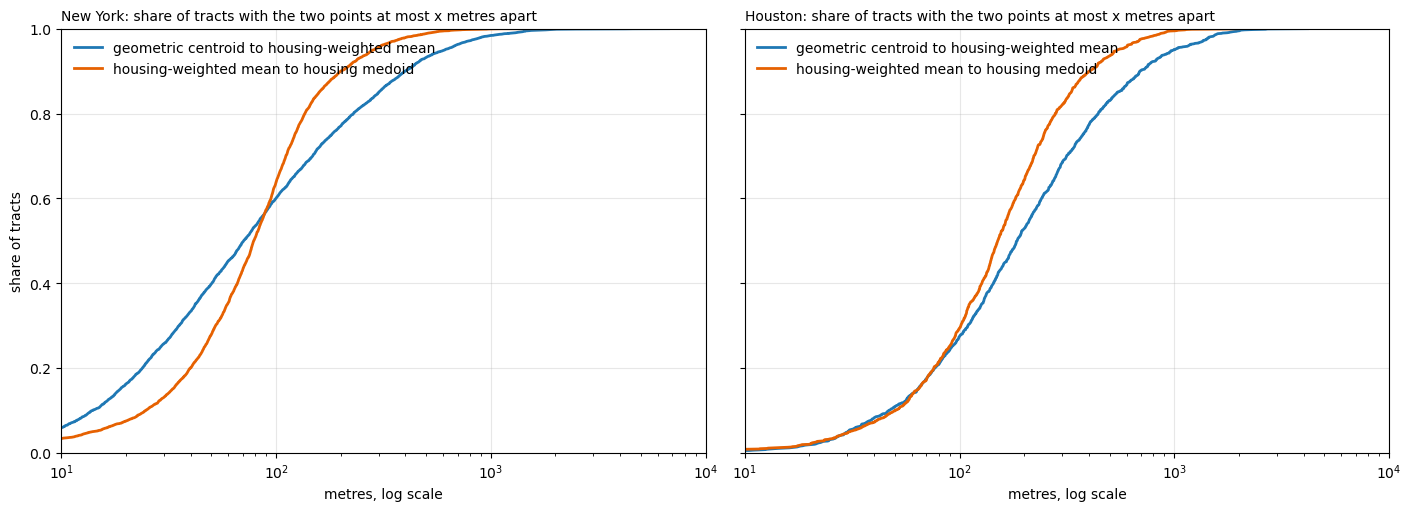

In [3]:
# Share of tracts whose candidate points lie within a given distance of each other, per area.
figure, axes = plt.subplots(ncols=len(AREAS), figsize=(7 * len(AREAS), 5), layout="constrained", sharey=True)
for axis, (area, points) in zip(axes, candidates.items()):
    for column, label, colour in (("centroid_to_weighted_m", "geometric centroid to housing-weighted mean", "#1f78b4"),
                                  ("weighted_to_medoid_m", "housing-weighted mean to housing medoid", "#e66101")):
        values = np.sort(points[column].dropna().to_numpy())
        axis.plot(values, np.arange(1, len(values) + 1) / len(values), label=label, color=colour, linewidth=2)
    axis.set_xscale("log")
    axis.set_xlim(10, 10000)
    axis.set_ylim(0, 1)
    axis.set_xlabel("metres, log scale")
    axis.set_title(f"{area}: share of tracts with the two points at most x metres apart", loc="left", fontsize=10)
    axis.grid(alpha=0.3)
    axis.legend(loc="upper left", frameon=False)
axes[0].set_ylabel("share of tracts");


## 2. Sensitivity: every tract routed from four origins, all tracts and the most split decile

Every tract with a housing-weighted mean is routed to the work points of 05.7 from each of the
four candidate origins, by transit at the departure of 05.3 and by car at the rush with
intersection delays, and the commuting flows of the tracts are joined to each result. All four
origins are given to cafein as they are and attached to the street network by its own linking,
so none is favoured by the snapping of 05.7; the used point differs from the routed one by the
few metres of that snap. The tracts with no housing unit, whose point is the old one of 05.3,
have no weighted mean or medoid and are left out of every origin.

The first table reports, per area and origin, the commuters reached, the commuters without
an itinerary, the share reached and the worker-weighted median minutes by mode; every figure
counts people, the workers of the LODES flows, never tracts, once over all tracts and once over the decile of
tracts with the largest mean-to-medoid distance, which are the ones where the choice of point
can matter. The decile is the sprawling tail of each area, large tracts in the outer counties,
so its reach by transit is low from every origin; the all-tract rows give the area-wide figure.
The second table sets the point the analysis uses, the weighted mean replaced by the medoid
where the mean stood on an empty block, against the weighted mean alone over all tracts: how
many tracts the rule moved, and how many commuters gain or lose a transit itinerary because of
it. The third table gives the per-tract differences against the housing-weighted point within
the decile.


In [4]:
ORIGINS = ["centroid", "weighted", "medoid", "used"]
MODES = {"transit": "transit", "car": "car, rush hour"}
SUBSETS = ["all tracts", "top decile"]


def weighted_median(values, weights):
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return values[order][np.searchsorted(cumulative, 0.5)]


def route(streets, transit_network, origins, destinations, departure):
    # Transit and rush-hour car minutes from the origins to the destinations, as one table per mode.
    started = time.time()
    car = TravelTimeMatrix(streets, origins, destinations, transport_mode="car", intersection_delays=True, profile="rush", output_time_units="minutes")
    print(f"car in {time.time() - started:.0f} s", end=", ")
    transit = TravelTimeMatrix(transit_network, origins, destinations, departure=departure, output_time_units="minutes")
    print(f"transit in {time.time() - started:.0f} s")
    return {"transit": pd.DataFrame(transit)[["from_id", "to_id", "travel_time"]], "car": pd.DataFrame(car)[["from_id", "to_id", "travel_time"]]}


decile = {}
measured_points = {}
results = {}
for area, spec in AREAS.items():
    points = candidates[area]
    measured = points.loc[points["weighted_to_medoid_m"].notna()]
    measured_points[area] = measured
    chosen = measured.loc[measured["weighted_to_medoid_m"] >= measured["weighted_to_medoid_m"].quantile(0.9)]
    decile[area] = chosen
    destinations = gpd.read_parquet(spec["folder"] / f"tract-points-work-snapped-{YEAR}.parquet")
    flows = pd.read_parquet(spec["folder"] / f"tract-od-{YEAR}.parquet")
    flows = flows.loc[flows["from_id"].isin(measured["tract"]) & flows["to_id"].isin(destinations["id"])].copy()
    flows["top decile"] = flows["from_id"].isin(chosen["tract"])
    land = tracts[area].set_index("tract")["land_km2"]
    print(f"{area}: {len(measured):,} tracts with a housing-weighted mean, {flows['workers'].sum():,} commuters "
          f"({flows['workers'].sum() / points['residents'].sum():.1%} of all); the top decile holds {len(chosen)} of them "
          f"(mean to medoid at least {chosen['weighted_to_medoid_m'].min():.0f} m) and {flows.loc[flows['top decile'], 'workers'].sum():,} commuters "
          f"({flows.loc[flows['top decile'], 'workers'].sum() / flows['workers'].sum():.1%}); median land area {land[chosen['tract']].median():.1f} km2 "
          f"in the decile against {land[measured['tract']].drop(chosen['tract']).median():.1f} km2 in the other tracts; "
          f"the used point is the medoid in {int(chosen['used_is_medoid'].sum())} decile tracts")
    streets = StreetNetwork.load(spec["streets"])
    transit_network = TransportNetwork.load(spec["transit"])
    results[area] = {}
    for origin in ORIGINS:
        origins = gpd.GeoDataFrame({"id": measured["tract"].to_numpy()},
                                   geometry=gpd.GeoSeries(measured[origin].to_numpy(), crs=spec["metric_crs"]).to_crs("EPSG:4326").to_numpy(), crs="EPSG:4326")
        print(f"{area}, {origin}: {len(origins):,} origins, ", end="")
        matrices = route(streets, transit_network, origins, destinations, spec["departure"])
        joined = flows.copy()
        for mode, matrix in matrices.items():
            joined = joined.merge(matrix.rename(columns={"travel_time": f"{mode}_min"}), on=["from_id", "to_id"], how="left")
        results[area][origin] = joined


def summary(joined):
    # Commuters routed, and per mode the commuters reached, the commuters without an itinerary, the share and the median minutes.
    row = {"commuters": joined["workers"].sum()}
    for mode in MODES:
        reached = joined[f"{mode}_min"].notna()
        row[f"{MODES[mode]}: commuters reached"] = joined.loc[reached, "workers"].sum()
        row[f"{MODES[mode]}: commuters without an itinerary"] = joined.loc[~reached, "workers"].sum()
        row[f"{MODES[mode]}: share of commuters reached"] = joined.loc[reached, "workers"].sum() / joined["workers"].sum()
        row[f"{MODES[mode]}: median minutes"] = weighted_median(joined.loc[reached, f"{mode}_min"].to_numpy(), joined.loc[reached, "workers"].to_numpy())
    return row


rows = []
for area in AREAS:
    for subset in SUBSETS:
        for origin in ORIGINS:
            joined = results[area][origin]
            if subset == "top decile":
                joined = joined.loc[joined["top decile"]]
            rows.append({"area": area, "tracts": subset, "origin": origin, **summary(joined)})
print("commuters reached and without an itinerary, and worker-weighted median minutes, by origin, over all tracts and over the top decile:")
pd.DataFrame(rows).set_index(["area", "tracts", "origin"]).round(3).T


New York: 4,552 tracts with a housing-weighted mean, 6,703,708 commuters (92.4% of all); the top decile holds 456 of them (mean to medoid at least 200 m) and 653,085 commuters (9.7%); median land area 4.1 km2 in the decile against 0.4 km2 in the other tracts; the used point is the medoid in 52 decile tracts


loading the network:   0%|          | 0/2 [00:02<?, ?it/s]

New York, centroid: 4,552 origins, 

street matrix:   0%|          | 0/4552 [00:02<?, ?it/s]

car in 147 s, 

travel_time_matrix:   5%|5         | 228/4552 [00:02<00:37, 113.82it/s]

... (36 outputs left out)

/tmp/marinflo/3155671/ipykernel_1552144/883000643.py:17: UserWarning: 1 origin point(s) are off the walking network and unreachable (48071710600)
  transit = TravelTimeMatrix(transit_network, origins, destinations, departure=departure, output_time_units="minutes")


transit in 25 s


commuters reached and without an itinerary, and worker-weighted median minutes, by origin, over all tracts and over the top decile:


area                                               New York               \
tracts                                           all tracts                
origin                                             centroid     weighted   
commuters                                       6703708.000  6703708.000   
transit: commuters reached                      6661855.000  6666976.000   
transit: commuters without an itinerary           41853.000    36732.000   
transit: share of commuters reached                   0.994        0.995   
transit: median minutes                              71.000       70.000   
car, rush hour: commuters reached               6618383.000  6626299.000   
car, rush hour: commuters without an itinerary    85325.000    77409.000   
car, rush hour: share of commuters reached            0.987        0.988   
car, rush hour: median minutes                       31.000       31.000   

area                                                                      \
tracts                                                                     
origin                                               medoid         used   
commuters                                       6703708.000  6703708.000   
transit: commuters reached                      6669322.000  6666976.000   
transit: commuters without an itinerary           34386.000    36732.000   
transit: share of commuters reached                   0.995        0.995   
transit: median minutes                              70.000       70.000   
car, rush hour: commuters reached               6621569.000  6626214.000   
car, rush hour: commuters without an itinerary    82139.000    77494.000   
car, rush hour: share of commuters reached            0.988        0.988   
car, rush hour: median minutes                       31.000       31.000   

area                                                                    \
tracts                                          top decile               
origin                                            centroid    weighted   
commuters                                       653085.000  653085.000   
transit: commuters reached                      641109.000  642747.000   
transit: commuters without an itinerary          11976.000   10338.000   
transit: share of commuters reached                  0.982       0.984   
transit: median minutes                            124.000     121.000   
car, rush hour: commuters reached               624775.000  629605.000   
car, rush hour: commuters without an itinerary   28310.000   23480.000   
car, rush hour: share of commuters reached           0.957       0.964   
car, rush hour: median minutes                      43.000      43.000   

area                                                                    \
tracts                                                                   
origin                                              medoid        used   
commuters                                       653085.000  653085.000   
transit: commuters reached                      645977.000  642747.000   
transit: commuters without an itinerary           7108.000   10338.000   
transit: share of commuters reached                  0.989       0.984   
transit: median minutes                            121.000     121.000   
car, rush hour: commuters reached               627494.000  629549.000   
car, rush hour: commuters without an itinerary   25591.000   23536.000   
car, rush hour: share of commuters reached           0.961       0.964   
car, rush hour: median minutes                      43.000      43.000   

area                                                Houston               \
tracts                                           all tracts                
origin                                             centroid     weighted   
commuters                                       2114669.000  2114669.000   
transit: commuters reached                      1461016.000  1473340.000   
transit: commute

In [5]:
# The point the analysis uses against the housing-weighted mean alone, over all tracts: the two
# origins differ only where the empty-block rule or the inside-the-polygon fallback moved the point.
def rule_against_mean(source, modes):
    # Reach and median minutes from the point used and from the weighted mean alone, all tracts, per area and mode.
    rows = []
    for area, spec in AREAS.items():
        measured = measured_points[area]
        apart = gpd.GeoSeries(measured["used"].to_numpy(), crs=spec["metric_crs"]).distance(gpd.GeoSeries(measured["weighted"].to_numpy(), crs=spec["metric_crs"])).to_numpy()
        moved = measured.loc[apart > 1, "tract"]
        used = source[area]["used"]
        weighted = source[area]["weighted"]
        for mode in modes:
            pair = used[["from_id", "to_id", "workers", f"{mode}_min"]].merge(weighted[["from_id", "to_id", f"{mode}_min"]], on=["from_id", "to_id"], suffixes=("_used", "_weighted"))
            with_used = pair[f"{mode}_min_used"].notna()
            with_weighted = pair[f"{mode}_min_weighted"].notna()
            in_moved = pair["from_id"].isin(moved)
            rows.append({
                "area": area, "mode": modes[mode],
                "tracts where the point differs": len(moved),
                "their commuters": pair.loc[in_moved, "workers"].sum(),
                "commuters routed": pair["workers"].sum(),
                "commuters reached, weighted mean alone": pair.loc[with_weighted, "workers"].sum(),
                "commuters reached, point used": pair.loc[with_used, "workers"].sum(),
                "share reached, weighted mean alone": pair.loc[with_weighted, "workers"].sum() / pair["workers"].sum(),
                "share reached, point used": pair.loc[with_used, "workers"].sum() / pair["workers"].sum(),
                "change, percentage points": 100 * (pair.loc[with_used, "workers"].sum() - pair.loc[with_weighted, "workers"].sum()) / pair["workers"].sum(),
                "commuters reached only from the point used": pair.loc[with_used & ~with_weighted, "workers"].sum(),
                "commuters reached only from the weighted mean": pair.loc[with_weighted & ~with_used, "workers"].sum(),
                "median minutes, weighted mean alone": weighted_median(pair.loc[with_weighted, f"{mode}_min_weighted"].to_numpy(), pair.loc[with_weighted, "workers"].to_numpy()),
                "median minutes, point used": weighted_median(pair.loc[with_used, f"{mode}_min_used"].to_numpy(), pair.loc[with_used, "workers"].to_numpy()),
            })
    return pd.DataFrame(rows).set_index(["area", "mode"]).T


print("the point used (weighted mean, or the medoid where the mean stood on an empty block) against the weighted mean alone, all tracts:")
rule_against_mean(results, MODES).round(3)


the point used (weighted mean, or the medoid where the mean stood on an empty block) against the weighted mean alone, all tracts:


area                                              New York                 \
mode                                               transit car, rush hour   
tracts where the point differs                     220.000        220.000   
their commuters                                 291160.000     291160.000   
commuters routed                               6703708.000    6703708.000   
commuters reached, weighted mean alone         6666976.000    6626299.000   
commuters reached, point used                  6666976.000    6626214.000   
share reached, weighted mean alone                   0.995          0.988   
share reached, point used                            0.995          0.988   
change, percentage points                            0.000         -0.001   
commuters reached only from the point used           0.000         45.000   
commuters reached only from the weighted mean        0.000        130.000   
median minutes, weighted mean alone                 70.000         31.000   
median minutes, point used                          70.000         31.000   

area                                               Houston                 
mode                                               transit car, rush hour  
tracts where the point differs                      97.000         97.000  
their commuters                                 139784.000     139784.000  
commuters routed                               2114669.000    2114669.000  
commuters reached, weighted mean alone         1473340.000    2106025.000  
commuters reached, point used                  1476125.000    2105929.000  
share reached, weighted mean alone                   0.697          0.996  
share reached, point used                            0.698          0.996  
change, percentage points                            0.132         -0.005  
commuters reached only from the point used        3191.000         85.000  
commuters reached only from the weighted mean      406.000        181.000  
median minutes, weighted mean alone                122.000         38.000  
median minutes, point used                         122.000         38.000

per-tract differences against the housing-weighted origin, top-decile tracts:


tracts  \
area     mode           origin against the housing-weighted point           
New York transit        centroid                                      456   
                        medoid                                        456   
                        used                                          456   
         car, rush hour centroid                                      456   
                        medoid                                        456   
                        used                                          456   
Houston  transit        centroid                                      145   
                        medoid                                        145   
                        used                                          145   
         car, rush hour centroid                                      145   
                        medoid                                        145   
                        used                                          145   

                                                                   median minutes: median absolute change  \
area     mode           origin against the housing-weighted point                                           
New York transit        centroid                                                                      0.0   
                        medoid                                                                        0.0   
                        used                                                                          0.0   
         car, rush hour centroid                                                                      1.0   
                        medoid                                                                        1.0   
                        used                                                                          0.0   
Houston  transit        centroid                                                                      7.0   
                        medoid                                                                        6.5   
                        used                                                                          0.0   
         car, rush hour centroid                                                                      2.0   
                        medoid                                                                        2.0   
                        used                                                                          0.0   

                                                                   median minutes: p90 absolute change  \
area     mode           origin against the housing-weighted point                                        
New York transit        centroid                                                                  27.0   
                        medoid                                                                    21.0   
                        used                                                                       0.0   
         car, rush hour centroid                                                                   4.0   
                        medoid                                                                     3.0   
                        used                                                                       1.0   
Houston  transit        centroid                                                                  58.1   
                        medoid                                                                    40.7   
                        used                                                                       6.7   
         car, rush hour centroid                                                                   7.0   
                        medoid                                                                     6.0   
                        used                                                       

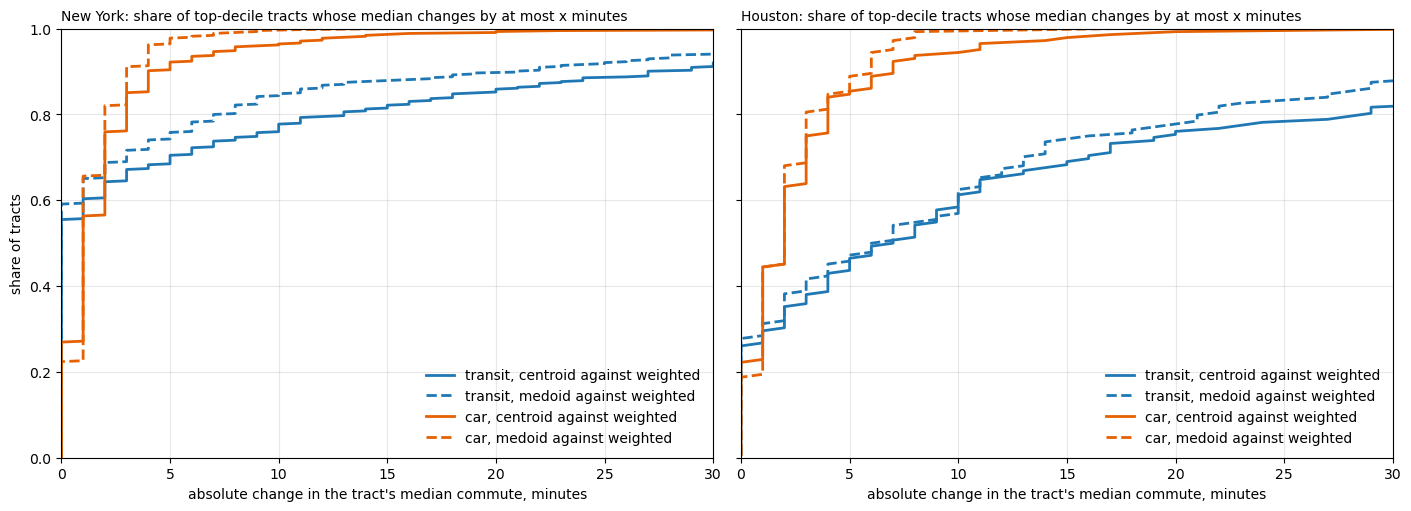

In [6]:
def in_decile(joined):
    return joined.loc[joined["top decile"]]


def per_tract(joined, mode):
    # Worker-weighted median minutes and share reached per home tract.
    reached = joined.loc[joined[f"{mode}_min"].notna()]
    minutes = reached.groupby("from_id").apply(lambda rows: weighted_median(rows[f"{mode}_min"].to_numpy(), rows["workers"].to_numpy()), include_groups=False)
    share = reached.groupby("from_id")["workers"].sum() / joined.groupby("from_id")["workers"].sum()
    return pd.DataFrame({"minutes": minutes, "share": share.fillna(0)})


differences = {}
rows = []
for area in AREAS:
    differences[area] = {}
    for mode in MODES:
        base = per_tract(in_decile(results[area]["weighted"]), mode)
        for origin in ("centroid", "medoid", "used"):
            other = per_tract(in_decile(results[area][origin]), mode).reindex(base.index)
            delta_minutes = (other["minutes"] - base["minutes"])
            delta_share = (other["share"] - base["share"])
            differences[area][(mode, origin)] = delta_minutes
            rows.append({"area": area, "mode": MODES[mode], "origin against the housing-weighted point": origin,
                         "tracts": len(base),
                         "median minutes: median absolute change": delta_minutes.abs().median(),
                         "median minutes: p90 absolute change": delta_minutes.abs().quantile(0.9),
                         "median minutes: largest change": delta_minutes.abs().max(),
                         "share reached: tracts changed by over 5 points": (delta_share.abs() > 0.05).mean()})
print("per-tract differences against the housing-weighted origin, top-decile tracts:")
display(pd.DataFrame(rows).set_index(["area", "mode", "origin against the housing-weighted point"]).round(2))

figure, axes = plt.subplots(ncols=len(AREAS), figsize=(7 * len(AREAS), 5), layout="constrained", sharey=True)
series = {("transit", "centroid"): ("transit, centroid against weighted", "#1f78b4", "-"), ("transit", "medoid"): ("transit, medoid against weighted", "#1f78b4", "--"),
          ("car", "centroid"): ("car, centroid against weighted", "#e66101", "-"), ("car", "medoid"): ("car, medoid against weighted", "#e66101", "--")}
for axis, area in zip(axes, AREAS):
    for key, (label, colour, style) in series.items():
        values = np.sort(differences[area][key].abs().dropna().to_numpy())
        axis.plot(values, np.arange(1, len(values) + 1) / len(values), label=label, color=colour, linestyle=style, linewidth=2)
    axis.set_xlim(0, 30)
    axis.set_ylim(0, 1)
    axis.set_xlabel("absolute change in the tract's median commute, minutes")
    axis.set_title(f"{area}: share of top-decile tracts whose median changes by at most x minutes", loc="left", fontsize=10)
    axis.grid(alpha=0.3)
    axis.legend(loc="lower right", frameon=False)
axes[0].set_ylabel("share of tracts");


## 3. The same routing with a 30-minute walk to and from the stops

cafein, like r5py, lets a transit itinerary start and end with a walk of up to 120 minutes
between the point and a stop. That cap is generous for a commute: a two-hour walk to the first
bus is an itinerary on paper, not a choice anyone makes. This step repeats the transit routing
of step 2, same origins, same work points, same departure, with that walk capped at
30 minutes at each end, set with cafein's walking-time option on the query; the 20-minute
transfer footpaths of the network are unchanged. The first table gives the share reached and
the worker-weighted median minutes under both caps, over all tracts and over the top decile,
so the figures of step 2 can be read against a cap closer to what commuters accept. The second
table repeats the comparison of the point used with the weighted mean alone under the
30-minute cap.


In [7]:
ACCESS_MINUTES = 30                 # the walk allowed from the origin to the first stop and from the last stop to the destination
DEFAULT_ACCESS_MINUTES = 120        # cafein's default, the cap behind every transit matrix so far

capped = {}
for area, spec in AREAS.items():
    measured = measured_points[area]
    destinations = gpd.read_parquet(spec["folder"] / f"tract-points-work-snapped-{YEAR}.parquet")
    transit_network = TransportNetwork.load(spec["transit"])
    capped[area] = {}
    for origin in ORIGINS:
        origins = gpd.GeoDataFrame({"id": measured["tract"].to_numpy()},
                                   geometry=gpd.GeoSeries(measured[origin].to_numpy(), crs=spec["metric_crs"]).to_crs("EPSG:4326").to_numpy(), crs="EPSG:4326")
        started = time.time()
        matrix = TravelTimeMatrix(transit_network, origins, destinations, departure=spec["departure"], max_walking_time=ACCESS_MINUTES, output_time_units="minutes")
        print(f"{area}, {origin}: transit with a {ACCESS_MINUTES}-minute access and egress walk in {time.time() - started:.0f} s")
        matrix = pd.DataFrame(matrix)[["from_id", "to_id", "travel_time"]].rename(columns={"travel_time": "transit_min"})
        capped[area][origin] = results[area][origin][["from_id", "to_id", "workers", "top decile"]].merge(matrix, on=["from_id", "to_id"], how="left")

rows = []
for area in AREAS:
    for subset in SUBSETS:
        for origin in ORIGINS:
            for cap, source in ((DEFAULT_ACCESS_MINUTES, results), (ACCESS_MINUTES, capped)):
                joined = source[area][origin]
                if subset == "top decile":
                    joined = joined.loc[joined["top decile"]]
                reached = joined["transit_min"].notna()
                rows.append({"area": area, "tracts": subset, "origin": origin, "access and egress cap, minutes": cap,
                             "commuters routed": joined["workers"].sum(),
                             "commuters reached": joined.loc[reached, "workers"].sum(),
                             "commuters without an itinerary": joined.loc[~reached, "workers"].sum(),
                             "share of commuters reached": joined.loc[reached, "workers"].sum() / joined["workers"].sum(),
                             "median minutes": weighted_median(joined.loc[reached, "transit_min"].to_numpy(), joined.loc[reached, "workers"].to_numpy())})
print(f"commuters reached and without a transit itinerary, and worker-weighted median minutes, by origin, with the access and egress walk capped at {DEFAULT_ACCESS_MINUTES} and at {ACCESS_MINUTES} minutes:")
display(pd.DataFrame(rows).set_index(["area", "tracts", "origin", "access and egress cap, minutes"]).unstack("access and egress cap, minutes").round(3))

print(f"the point used against the weighted mean alone, all tracts, transit with the {ACCESS_MINUTES}-minute cap:")
rule_against_mean(capped, {"transit": "transit"}).round(3)


loading the network:   0%|          | 0/2 [00:02<?, ?it/s]

travel_time_matrix:  10%|#         | 456/4552 [00:02<00:17, 227.62it/s]

New York, centroid: transit with a 30-minute access and egress walk in 29 s


travel_time_matrix:   5%|5         | 228/4552 [00:02<00:37, 113.83it/s]

New York, weighted: transit with a 30-minute access and egress walk in 24 s


travel_time_matrix:   5%|5         | 228/4552 [00:02<00:37, 113.81it/s]

... (10 outputs left out)

commuters reached and without a transit itinerary, and worker-weighted median minutes, by origin, with the access and egress walk capped at 120 and at 30 minutes:


commuters routed          commuters reached  \
access and egress cap, minutes              30       120               30    
area     tracts     origin                                                   
Houston  all tracts centroid            2114669  2114669            642409   
                    medoid              2114669  2114669            656888   
                    used                2114669  2114669            662398   
                    weighted            2114669  2114669            661840   
         top decile centroid             242631   242631             27235   
                    medoid               242631   242631             31751   
                    used                 242631   242631             33467   
                    weighted             242631   242631             33799   
New York all tracts centroid            6703708  6703708           5976450   
                    medoid              6703708  6703708           6065740   
                    used                6703708  6703708           6056299   
                    weighted            6703708  6703708           6056289   
         top decile centroid             653085   653085            417176   
                    medoid               653085   653085            464118   
                    used                 653085   653085            462640   
                    weighted             653085   653085            460854   

                                        commuters without an itinerary  \
access and egress cap, minutes      120                            30    
area     tracts     origin                                               
Houston  all tracts centroid    1461016                        1472260   
                    medoid      1483299                        1457781   
                    used        1476125                        1452271   
                    weighted    1473340                        1452829   
         top decile centroid     116673                         215396   
                    medoid       123427                         210880   
                    used         125300                         209164   
                    weighted     122502                         208832   
New York all tracts centroid    6661855                         727258   
                    medoid      6669322                         637968   
                    used        6666976                         647409   
                    weighted    6666976                         647419   
         top decile centroid     641109                         235909   
                    medoid       645977                         188967   
                    used         642747                         190445   
                    weighted     642747                         192231   

                                       share of commuters reached         \
access and egress cap, minutes     120                        30     120   
area     tracts     origin                                                 
Houston  all tracts centroid    653653                      0.304  0.691   
                    medoid      631370                      0.311  0.701   
                    used        638544                      0.313  0.698   
                    weighted    641329                      0.313  0.697   
         top decile centroid    125958                      0.112  0.481   
                    medoid      119204                      0.131  0.509   
                    used        117331                      0.138  0.516   
                    weighted    120129                      0.139  0.505   
New York all tracts centroid     41853                      0.892  0.994   
                    medoid       34386                      0.905  0.995   
                    used         36732                      0.903  0.995   
                    weighted     36732                      0.903  0.995   
 

the point used against the weighted mean alone, all tracts, transit with the 30-minute cap:


area,New York,Houston
mode,transit,transit
tracts where the point differs,220.000,97.000
their commuters,291160.000,139784.000
commuters routed,6703708.000,2114669.000
"commuters reached, weighted mean alone",6056289.000,661840.000
"commuters reached, point used",6056299.000,662398.000
"share reached, weighted mean alone",0.903,0.313
"share reached, point used",0.903,0.313
"change, percentage points",0.000,0.026
commuters reached only from the point used,2844.000,1241.000


## References

Check each entry against the journal's style and the publisher's record before submission.

- Abowd, J. M., Ashmead, R., Cumings-Menon, R., Garfinkel, S., Heineck, M., Heiss, C., Johns, R., Kifer, D., Leclerc, P., Machanavajjhala, A., Moran, B., Sexton, W., Spence, M. and Zhuravlev, P. (2022). The 2020 Census Disclosure Avoidance System TopDown Algorithm. *Harvard Data Science Review*, Special Issue 2.
- Apparicio, P., Abdelmajid, M., Riva, M. and Shearmur, R. (2008). Comparing alternative approaches to measuring the geographical accessibility of urban health services: distance types and aggregation-error issues. *International Journal of Health Geographics*, 7, 7.
- Current, J. R. and Schilling, D. A. (1987). Elimination of source A and B errors in p-median location problems. *Geographical Analysis*, 19(2), 95–110.
- Graham, M. R., Kutzbach, M. J. and McKenzie, B. (2014). Design comparison of LODES and ACS commuting data. U.S. Census Bureau, Center for Economic Studies Working Paper CES-WP-14-38.
- Hakimi, S. L. (1964). Optimum locations of switching centers and the absolute centers and medians of a graph. *Operations Research*, 12(3), 450–459.
- Hewko, J., Smoyer-Tomic, K. E. and Hodgson, M. J. (2002). Measuring neighbourhood spatial accessibility to urban amenities: does aggregation error matter? *Environment and Planning A*, 34(7), 1185–1206.
- Hillsman, E. L. and Rhoda, R. (1978). Errors in measuring distances from populations to service centers. *Annals of Regional Science*, 12(3), 74–88.
- Hodgson, M. J., Shmulevitz, F. and Körkel, M. (1997). Aggregation error effects on the discrete-space p-median model: the case of Edmonton, Canada. *The Canadian Geographer*, 41(4), 415–428.
- Kaufman, L. and Rousseeuw, P. J. (1990). *Finding Groups in Data: An Introduction to Cluster Analysis*. Wiley, New York. Chapter 2, partitioning around medoids.
- Machanavajjhala, A., Kifer, D., Abowd, J., Gehrke, J. and Vilhuber, L. (2008). Privacy: theory meets practice on the map. *Proceedings of the 24th IEEE International Conference on Data Engineering*, 277–286.
- Openshaw, S. (1984). *The Modifiable Areal Unit Problem*. Concepts and Techniques in Modern Geography 38. Geo Books, Norwich.
- U.S. Census Bureau (2021). *2020 Census Redistricting Data (Public Law 94-171) Summary File: Technical Documentation*. Washington, DC. Section on disclosure avoidance and invariants.
- U.S. Census Bureau (2023). *LEHD Origin-Destination Employment Statistics (LODES) Technical Documentation, version 8*. Washington, DC.
